# S&P 500 Regime Prediction: the complete project in one notebook

**Team:** Ahmed Said · Fares Dhiab · Farouk Guerdelli · Hichem Ferjani · Mahdi Fakhfakh
**Repository:** [github.com/AhmedxSaid/sp500-regime-prediction](https://github.com/AhmedxSaid/sp500-regime-prediction)

This notebook runs the whole project from raw data to the final holdout test, in the order of the report's chapters:

| Part | Content |
|---|---|
| 0 | Setup and configuration |
| 1 | Business understanding |
| 2 | Data understanding |
| 3 | Data preprocessing |
| 4 | Regime labels, targets and features |
| 5 | EDA and statistical testing |
| 6 | Feature selection (SPY volume, VIX) |
| 7 | Modeling: walk-forward validation 1980–2021 |
| 8 | Interpretation and per-crisis results |
| 9 | Final holdout test, 2022–2026 |
| 10 | Conclusions |

The function definitions below are the same code as the repository's `src/sp500/` modules and scripts, so the results match the report. It needs about 6–8 minutes to run from top to bottom. If the data files are not next to it (e.g. in Google Colab), it downloads them from the GitHub repository.

```
pip install numpy pandas pyarrow scipy statsmodels scikit-learn lightgbm hmmlearn matplotlib seaborn
```

## 0. Setup and configuration

In [1]:
import sys, time, warnings, urllib.request
from pathlib import Path
from typing import Iterator

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
import logging
logging.getLogger("hmmlearn").setLevel(logging.ERROR)  # silence "Model is not converging" notes
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
NOTEBOOK_START = time.time()

In [2]:
# Paths: the notebook lives in notebooks/; the raw data in data/raw/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = ROOT / "data" / "raw"
GITHUB_RAW = "https://raw.githubusercontent.com/AhmedxSaid/sp500-regime-prediction/main/data/raw"

# Settings: all fixed before any model result was seen (src/sp500/config.py)
TICKERS = {
    "gspc": "^GSPC",       # S&P 500 price index
    "sp500tr": "^SP500TR", # S&P 500 total return index
    "spy": "SPY",          # SPDR S&P 500 ETF
    "es": "ES=F",          # E-mini S&P 500 continuous futures
    "vix": "^VIX",         # CBOE Volatility Index (30-day implied vol), from 1990
}


TRADING_DAYS = 252


FFILL_LIMIT = 2


BEAR_THRESHOLD = 0.20


BEAR_MERGE_MAX_GAP = 126


STRESS_WINDOW = 21


STRESS_QUANTILE = 0.80


STRESS_LOOKBACK = 5 * TRADING_DAYS


STRESS_MIN_HISTORY = 5 * TRADING_DAYS


STRESS_FIXED_VOL = 0.25


HORIZONS = (5, 21)


HOLDOUT_START = "2022-01-01"


FEATURES_MAIN = [
    "ret_1d", "mom_1m", "mom_3m", "mom_12m",          # returns / momentum
    "dist_ma50", "dist_ma200",                          # trend
    "drawdown", "below_peak_regime",                    # drawdown
    "rv_21d", "rv_63d", "parkinson_21d", "rv_vs_5y_p80",  # volatility
    "gap_open",                                         # overnight gap
]


FEATURE_GROUPS = {
    "spy_volume": ["spy_vol_ratio_20d"],                    # from 1993
    "vix": ["vix", "vix_rv_spread", "vix_chg_5d"],          # from 1990
}


GROUP_MIN_GAIN = 0.01


GROUP_MAX_ONSET_LOSS = 0.01


MODEL_START = "1962-01-01"


FIRST_TEST_YEAR = 1980


WALK_FORWARD_GAP = 21


SVM_TRAIN_EVERY = 5

## 1. Business understanding

We predict the S&P 500's **market regime** 5 and 21 trading days ahead, not its price:

- **Bear market:** a fall of 20% or more from a peak (main label: peak to trough).
- **Stressed market:** 21-day realized volatility above the 80th percentile of the previous 5 years.

Each regime also has a robustness label (`bear_merged`, `stressed_fixed`); conclusions must hold on both.

| Research question | Answered in |
|---|---|
| RQ1: How often and how persistently is the market in each regime? | Parts 4–5 |
| RQ2: Which features relate to future regimes? | Part 5 |
| RQ3: What data quality issues exist and how are they treated? | Parts 2–3 |
| RQ4: Do models beat simple baselines? | Parts 7 and 9 |
| RQ5: Do SPY volume or the VIX help? | Part 6 |
| RQ6: How does an SVM compare with simpler models? | Part 7 |

## 2. Data understanding

Five daily series from Yahoo Finance (downloaded 2026-10-25, through 2026-10-23), saved as CSV in `data/raw/`.

In [3]:
# Download the CSV snapshot from GitHub if it is not next to the notebook
DATA_RAW.mkdir(parents=True, exist_ok=True)
for name in TICKERS:
    path = DATA_RAW / f"{name}.csv"
    if not path.exists():
        urllib.request.urlretrieve(f"{GITHUB_RAW}/{name}.csv", path)
        print("downloaded", path.name)

def raw_path(name: str):
    return DATA_RAW / f"{name}.csv"


def load_raw(name: str) -> pd.DataFrame:
    df = pd.read_csv(raw_path(name), parse_dates=["date"], index_col="date")
    df.columns = [c.lower() for c in df.columns]
    return df

raw = {name: load_raw(name) for name in TICKERS}
pd.DataFrame({name: {"ticker": TICKERS[name], "rows": len(df), "first": df.index.min().date(),
                     "last": df.index.max().date()} for name, df in raw.items()}).T

,ticker,rows,first,last
gspc,^GSPC,24821,1927-12-30,2026-10-23
sp500tr,^SP500TR,9776,1988-01-04,2026-10-23
spy,SPY,8492,1993-01-29,2026-10-23
es,ES=F,6590,2000-09-18,2026-10-23
vix,^VIX,9273,1990-01-02,2026-10-23


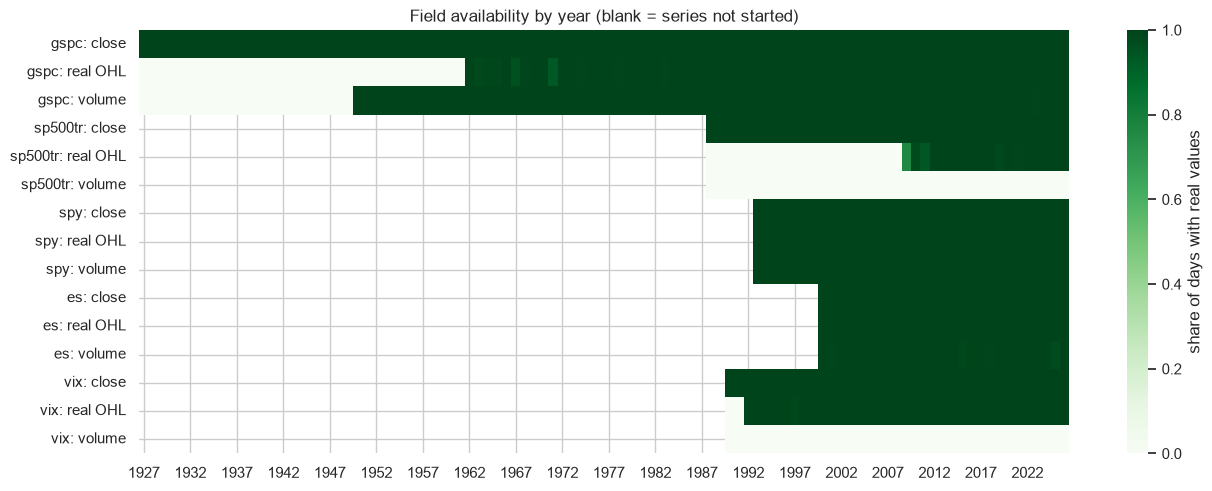

In [4]:
# Which fields hold real values, by year (open = high = low = close means fake OHL)
def usable(df):
    flat = (df["open"] == df["high"]) & (df["high"] == df["low"]) & (df["low"] == df["close"])
    return pd.DataFrame({"close": df["close"].notna(), "real OHL": ~flat, "volume": df["volume"] > 0}, index=df.index)

cov = {}
for name, df in raw.items():
    u = usable(df).groupby(df.index.year).mean()
    for field in u.columns:
        cov[f"{name}: {field}"] = u[field]
cov = pd.DataFrame(cov).reindex(range(1927, 2027)).T
fig, ax = plt.subplots(figsize=(15, 5.5))
sns.heatmap(cov, cmap="Greens", vmin=0, vmax=1, xticklabels=5, ax=ax, cbar_kws={"label": "share of days with real values"})
ax.set_title("Field availability by year (blank = series not started)")
ax.set_xlabel("")
plt.show()

In [5]:
# Initial quality checks on the raw files
rows = []
for name, df in raw.items():
    flat = (df["open"] == df["high"]) & (df["high"] == df["low"]) & (df["low"] == df["close"])
    rows.append({"series": name, "duplicate dates": int(df.index.duplicated().sum()),
                 "missing close": int(df["close"].isna().sum()),
                 "non-positive prices": int((df[["open", "high", "low", "close"]] <= 0).sum().sum()),
                 "flat OHLC rows": int(flat.sum()), "zero volume rows": int((df["volume"] <= 0).sum())})
pd.DataFrame(rows).set_index("series")

,duplicate dates,missing close,non-positive prices,flat OHLC rows,zero volume rows
series,,,,,
gspc,0,0,0,8547,5497
sp500tr,0,0,0,5379,9776
spy,0,0,0,0,0
es,0,0,0,0,11
vix,0,0,0,508,9273


## 3. Data preprocessing

Cleaning (`src/sp500/data_prep.py`): duplicates removed, fake open/high/low and zero volume set to missing, all series aligned on the ^GSPC trading calendar (prices forward-filled at most 2 days, only on days a series has no row), suspected bad prints corrected and flagged, futures roll days flagged.

In [6]:
PRICE_COLS = ["open", "high", "low", "close", "adj_close"]


KEEP_COLS = PRICE_COLS + ["volume"]


def clean_ohlcv(df: pd.DataFrame, name: str) -> tuple[pd.DataFrame, dict]:
    """Basic cleaning plus a dict of quality-check counts."""
    df = df[~df.index.duplicated(keep="last")].sort_index().copy()
    report: dict = {
        "series": name,
        "rows": len(df),
        "start": df.index.min().date(),
        "end": df.index.max().date(),
    }

    price_cols = [c for c in PRICE_COLS if c in df.columns]
    non_pos = df[price_cols] <= 0
    report["non_positive_prices"] = int(non_pos.to_numpy().sum())
    df[price_cols] = df[price_cols].mask(non_pos)

    if {"open", "high", "low", "close"}.issubset(df.columns):
        # Before ~1962 Yahoo stores ^GSPC open/high/low equal to the close
        flat = (df["open"] == df["high"]) & (df["high"] == df["low"]) & (df["low"] == df["close"])
        report["flat_ohlc_rows"] = int(flat.sum())
        df.loc[flat, ["open", "high", "low"]] = np.nan

        bad_range = (df["high"] < df["low"]) | (df["close"] > df["high"] * 1.0001) | (
            df["close"] < df["low"] * 0.9999
        )
        report["inconsistent_hlc_rows"] = int(bad_range.sum())

    if "volume" in df.columns:
        zero_vol = df["volume"] <= 0
        report["zero_volume_rows"] = int(zero_vol.sum())
        df["volume"] = df["volume"].mask(zero_vol)

    log_ret = np.log(df["close"]).diff()
    report["missing_close"] = int(df["close"].isna().sum())
    report["moves_gt_15pct"] = int((log_ret.abs() > 0.15).sum())
    report["largest_up_move"] = float(log_ret.max())
    report["largest_down_move"] = float(log_ret.min())
    report["largest_down_date"] = log_ret.idxmin().date() if log_ret.notna().any() else None

    return df[[c for c in KEEP_COLS if c in df.columns]], report


def find_bad_prints(
    close: pd.Series,
    others: tuple[pd.Series, ...] = (),
    min_move: float = 0.03,
    z_today: float = 5.0,
    z_next: float = 4.5,
    window: int = 63,
) -> pd.Series:
    """Flag suspected bad prints: one-day spikes that fully reverse the next day.

    A day is flagged when
      - the move is > `min_move` and is reversed the next day (net change < 25% of the move),
      - both moves are huge compared with the previous `window` days' volatility
        (>= `z_today` and >= `z_next` standard deviations), so it is not a normal day in a
        volatile market (real crash days like 1929-10-29 happen when volatility is already high),
      - and no other source in `others` confirms it (same direction, at least half the size).
    """
    r = np.log(close).diff()
    nxt = r.shift(-1)
    vol = r.rolling(window).std().shift(1)  # past volatility only, excluding today
    spike = (
        (r.abs() > min_move)
        & (nxt.abs() > min_move)
        & (np.sign(r) != np.sign(nxt))
        & ((r + nxt).abs() < 0.25 * r.abs())
        & (r.abs() / vol >= z_today)
        & (nxt.abs() / vol >= z_next)
    )
    for other in others:
        ro = np.log(other.reindex(close.index)).diff()
        confirmed = (np.sign(ro) == np.sign(r)) & (ro.abs() > 0.5 * r.abs())
        spike &= ~confirmed
    return spike.fillna(False).astype(bool)


def es_roll_window(index: pd.DatetimeIndex, days_before_expiry: int = 8, half_width: int = 2) -> pd.Series:
    """Flag trading days around the quarterly E-mini roll.

    ES contracts expire on the 3rd Friday of Mar/Jun/Sep/Dec, and volume moves to the
    next contract about 8 calendar days earlier. The continuous ES=F series can jump
    then, so returns in a +/- `half_width` trading-day window are unreliable.
    """
    flag = pd.Series(0, index=index, name="es_roll_window", dtype="int8")
    if len(index) == 0:
        return flag
    for year in range(index.min().year, index.max().year + 1):
        for month in (3, 6, 9, 12):
            days = pd.date_range(f"{year}-{month:02d}-01", periods=21, freq="D")
            third_friday = days[days.weekday == 4][2]
            roll = third_friday - pd.Timedelta(days=days_before_expiry)
            pos = index.searchsorted(roll)
            lo, hi = max(pos - half_width, 0), min(pos + half_width + 1, len(index))
            if lo < len(index):
                flag.iloc[lo:hi] = 1
    return flag


def build_dataset() -> tuple[pd.DataFrame, pd.DataFrame]:
    frames: dict[str, pd.DataFrame] = {}
    reports = []
    for name in TICKERS:
        path = raw_path(name)
        if not path.exists():
            print(f"[skip] {path.name} not found (run python -m sp500.data_download)")
            continue
        df, rep = clean_ohlcv(load_raw(name), name)
        frames[name] = df
        reports.append(rep)

    if "gspc" not in frames:
        raise FileNotFoundError("data/raw/gspc.csv is required as the master calendar")

    calendar = frames["gspc"].index
    aligned = []
    for name, df in frames.items():
        a = df.reindex(calendar)
        price_cols = [c for c in PRICE_COLS if c in a.columns]
        # Fill only short calendar gaps: days the series has no row for, inside its own history.
        # Values blanked on purpose during cleaning (e.g. fake pre-1962 OHL) must stay NaN.
        first, last = df.index.min(), df.index.max()
        absent = ~a.index.isin(df.index) & (a.index >= first) & (a.index <= last)
        filled = a[price_cols].ffill(limit=FFILL_LIMIT)
        a.loc[absent, price_cols] = filled.loc[absent]
        a.columns = [f"{name}_{c}" for c in a.columns]
        aligned.append(a)

    data = pd.concat(aligned, axis=1)

    # Suspected bad prints in the main series: replace the close with the geometric midpoint of
    # its neighbours and flag the row. Other sources (from 1988) are used to confirm real moves.
    others = tuple(data[c] for c in ("sp500tr_close", "spy_close", "es_close") if c in data.columns)
    bad = find_bad_prints(data["gspc_close"], others)
    if bad.any():
        prev_c, next_c = data["gspc_close"].shift(1), data["gspc_close"].shift(-1)
        fixed = np.sqrt(prev_c * next_c).round(4)
        for col in ("gspc_close", "gspc_adj_close"):
            if col in data.columns:
                data.loc[bad, col] = fixed[bad]
        print(f"[fix] {int(bad.sum())} suspected bad prints in gspc_close replaced: "
              + ", ".join(str(d.date()) for d in data.index[bad]))
    data["gspc_bad_print_fixed"] = bad.astype("int8")
    for rep in reports:
        rep["bad_prints_fixed"] = int(bad.sum()) if rep["series"] == "gspc" else 0

    if "es" in frames:
        data["es_roll_window"] = es_roll_window(calendar)
    data.index.name = "date"
    return data, pd.DataFrame(reports)

In [7]:
daily, quality = build_dataset()
print("cleaned daily table:", daily.shape)
quality.set_index("series")

[fix] 4 suspected bad prints in gspc_close replaced: 1935-04-16, 1935-08-16, 1936-09-16, 1961-04-17
cleaned daily table: (24821, 32)


,rows,start,end,non_positive_prices,flat_ohlc_rows,inconsistent_hlc_rows,zero_volume_rows,missing_close,moves_gt_15pct,largest_up_move,largest_down_move,largest_down_date,bad_prints_fixed
series,,,,,,,,,,,,,
gspc,24821,1927-12-30,2026-10-23,0,8547,0,5497,0,2,0.154,-0.229,1987-10-19,4
sp500tr,9776,1988-01-04,2026-10-23,0,5379,0,9776,0,0,0.110,-0.128,2020-03-16,0
spy,8492,1993-01-29,2026-10-23,0,0,0,0,0,0,0.136,-0.116,2020-03-16,0
es,6590,2000-09-18,2026-10-23,0,0,10,11,0,0,0.132,-0.110,2020-03-16,0
vix,9273,1990-01-02,2026-10-23,0,508,0,9273,0,321,0.768,-0.442,2025-04-09,0


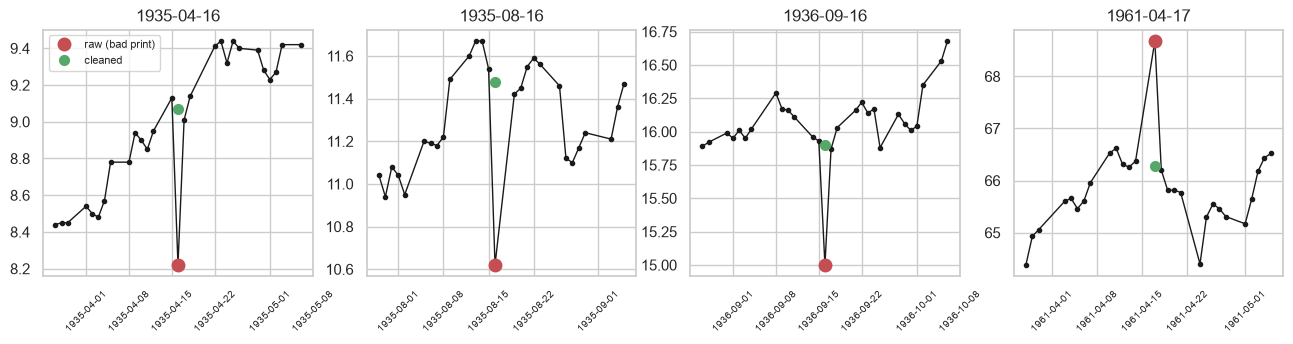

In [8]:
# The 4 suspected bad prints: one-day spikes in calm markets that fully reverse the next day
c = raw["gspc"]["close"]
flagged = daily.index[daily["gspc_bad_print_fixed"] == 1]
fig, axes = plt.subplots(1, len(flagged), figsize=(16, 3.2))
for ax, d in zip(np.atleast_1d(axes), flagged):
    w = c.loc[d - pd.Timedelta(days=20): d + pd.Timedelta(days=20)]
    ax.plot(w.index, w.values, marker=".", color="k", lw=1)
    ax.plot(d, c.loc[d], "o", color="C3", ms=9, label="raw (bad print)")
    ax.plot(d, daily.loc[d, "gspc_close"], "o", color="C2", ms=7, label="cleaned")
    ax.set_title(str(d.date()))
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
np.atleast_1d(axes)[0].legend(fontsize=8)
plt.show()

In [9]:
# Cross-source consistency: the five sources should agree
rets = np.log(daily[[f"{n}_close" for n in TICKERS]]).diff()
rets.columns = list(TICKERS)
print("daily return correlation with ^GSPC (common period):")
print(rets.loc["2000-09-19":].corr()["gspc"].round(4).to_string())
tr = daily["sp500tr_close"].dropna()
px = daily.loc[tr.index, "gspc_close"]
yrs = (tr.index[-1] - tr.index[0]).days / 365.25
print(f"\ntotal return vs price index, annual growth: {((tr.iloc[-1]/tr.iloc[0])**(1/yrs)-1):.2%} vs "
      f"{((px.iloc[-1]/px.iloc[0])**(1/yrs)-1):.2%} -> dividends")

daily return correlation with ^GSPC (common period):
gspc       1.000
sp500tr    1.000
spy        0.988
es         0.974
vix       -0.733

total return vs price index, annual growth: 11.44% vs 9.14% -> dividends


## 4. Regime labels, targets and features

`src/sp500/labels.py` and `src/sp500/features.py`. The target is the label shifted **forward** by *h* days; features use only data known at the close of day *t*.

In [10]:
def bear_market_labels(
    close: pd.Series, threshold: float = BEAR_THRESHOLD, method: str = "peak_to_trough"
) -> pd.Series:
    """Label each day 1 (bear) or 0 (bull).

    method="peak_to_trough": classic dating. A bear runs from the peak before a fall of at
        least `threshold` to the trough; it is confirmed over once price rises `threshold`
        above the trough. Uses hindsight, so it is a LABEL only, never a feature.
    method="recovery": a bear starts on the day price closes `threshold` below its peak and
        ends when price gets back to that peak. Causal (known at day t), so it can also be
        used as a current-state feature or baseline.
    """
    if method not in {"peak_to_trough", "recovery"}:
        raise ValueError("method must be 'peak_to_trough' or 'recovery'")

    s = close.dropna()
    v = s.to_numpy(dtype=float)
    n = len(v)
    bear = np.zeros(n, dtype=bool)
    in_bear = False
    peak_i = trough_i = start_i = 0

    for i in range(1, n):
        p = v[i]
        if not in_bear:
            if p > v[peak_i]:
                peak_i = i
            elif p <= v[peak_i] * (1 - threshold):
                in_bear = True
                trough_i = i
                start_i = peak_i if method == "peak_to_trough" else i
        else:
            if p < v[trough_i]:
                trough_i = i
            if method == "peak_to_trough":
                if p >= v[trough_i] * (1 + threshold):
                    bear[start_i : trough_i + 1] = True
                    in_bear = False
                    peak_i = i
            else:
                if p >= v[peak_i]:
                    bear[start_i:i] = True
                    in_bear = False
                    peak_i = i

    if in_bear:  # bear still ongoing at the end of the sample
        bear[start_i:] = True

    out = pd.Series(bear.astype("int8"), index=s.index, name=f"bear_{method}")
    return out.reindex(close.index)


def merge_bear_episodes(
    bear: pd.Series, close: pd.Series, max_gap: int = BEAR_MERGE_MAX_GAP
) -> pd.Series:
    """Merge bear markets separated by a short, failed rally (robustness label).

    Two consecutive bear episodes are merged (the bull days between them become bear) when
      - the bull gap between them is at most `max_gap` trading days, and
      - price never closes above the peak where the (merged) bear started.
    Uses hindsight, like `bear_market_labels(method="peak_to_trough")`: LABEL only.
    """
    s = bear.fillna(0).astype(int).to_numpy().copy()
    price = close.reindex(bear.index).ffill().to_numpy(dtype=float)
    n = len(s)

    # (start, end) positions of each run of 1s
    runs, i = [], 0
    while i < n:
        if s[i] == 1:
            j = i
            while j + 1 < n and s[j + 1] == 1:
                j += 1
            runs.append([i, j])
            i = j + 1
        else:
            i += 1

    merged = []
    for start, end in runs:
        if merged:
            prev_start, prev_end = merged[-1]
            gap = start - prev_end - 1
            peak = price[prev_start]
            gap_max = np.nanmax(price[prev_end + 1 : start]) if gap > 0 else -np.inf
            if gap <= max_gap and gap_max <= peak:
                merged[-1][1] = end
                continue
        merged.append([start, end])

    out = np.zeros(n, dtype="int8")
    for start, end in merged:
        out[start : end + 1] = 1
    result = pd.Series(out, index=bear.index, name="bear_merged")
    return result.where(bear.notna())


def realized_vol(close: pd.Series, window: int = STRESS_WINDOW) -> pd.Series:
    """Annualized close-to-close realized volatility."""
    r = np.log(close).diff()
    return r.rolling(window).std() * np.sqrt(TRADING_DAYS)


def stress_labels(
    close: pd.Series,
    window: int = STRESS_WINDOW,
    quantile: float = STRESS_QUANTILE,
    lookback: int | None = STRESS_LOOKBACK,
    min_history: int = STRESS_MIN_HISTORY,
) -> pd.DataFrame:
    """Stressed = 1 when realized vol is above the `quantile` of PAST realized vol.

    The threshold uses the previous `lookback` days (rolling), or all history if `lookback` is
    None (expanding). It is shifted by one day, so it only uses data before day t.
    Returns a DataFrame with the realized vol, the threshold and the label (NaN until enough history).
    """
    rv = realized_vol(close, window)
    past = rv.expanding(min_periods=min_history) if lookback is None else \
        rv.rolling(lookback, min_periods=min_history)
    threshold = past.quantile(quantile).shift(1)
    label = (rv > threshold).astype(float)
    label[rv.isna() | threshold.isna()] = np.nan
    return pd.DataFrame({"rv": rv, "stress_threshold": threshold, "stressed": label})


def stress_fixed_labels(close: pd.Series, level: float = STRESS_FIXED_VOL,
                        window: int = STRESS_WINDOW) -> pd.Series:
    """Robustness label: stressed = 1 when annualized realized vol is above a fixed `level`."""
    rv = realized_vol(close, window)
    label = (rv > level).astype(float)
    label[rv.isna()] = np.nan
    return label.rename("stressed_fixed")


def make_target(label: pd.Series, horizon: int) -> pd.Series:
    """Regime `horizon` days ahead, aligned to day t. Only the label is shifted, never the features."""
    return label.shift(-horizon).rename(f"target_{label.name}_h{horizon}")


def episodes(label: pd.Series) -> pd.DataFrame:
    """Start, end and length (trading days) of each run of 1s in a 0/1 label."""
    s = label.fillna(0).astype(int)
    change = s.diff().fillna(s.iloc[0] if len(s) else 0)
    starts = s.index[change == 1]
    ends = s.index[(change == -1).shift(-1, fill_value=False)]
    if len(ends) < len(starts):  # ongoing at the end
        ends = ends.append(pd.DatetimeIndex([s.index[-1]]))
    rows = []
    for a, b in zip(starts, ends):
        rows.append({"start": a, "end": b, "days": int(s.loc[a:b].sum())})
    return pd.DataFrame(rows)

In [11]:
MOMENTUM_WINDOWS = {"1m": 21, "3m": 63, "6m": 126, "12m": 252}


TARGET_LABELS = ("bear", "bear_merged", "stressed", "stressed_fixed")


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    c = df["gspc_close"]
    log_c = np.log(c)
    r = log_c.diff()

    f = pd.DataFrame(index=df.index)
    f["ret_1d"] = r
    for name, w in MOMENTUM_WINDOWS.items():
        f[f"mom_{name}"] = log_c.diff(w)
    for w in (50, 200):
        f[f"dist_ma{w}"] = c / c.rolling(w).mean() - 1
    f["drawdown"] = c / c.cummax() - 1
    f["rv_21d"] = r.rolling(21).std() * np.sqrt(TRADING_DAYS)
    f["rv_63d"] = r.rolling(63).std() * np.sqrt(TRADING_DAYS)

    if {"gspc_open", "gspc_high", "gspc_low"}.issubset(df.columns):
        o, h, l = df["gspc_open"], df["gspc_high"], df["gspc_low"]
        hl = np.log(h / l)
        co = np.log(c / o)
        # range-based volatility estimators (need real OHLC, i.e. from ~1962)
        f["parkinson_21d"] = np.sqrt((hl**2).rolling(21).mean() / (4 * np.log(2)) * TRADING_DAYS)
        gk = 0.5 * hl**2 - (2 * np.log(2) - 1) * co**2
        f["garman_klass_21d"] = np.sqrt(gk.rolling(21).mean().clip(lower=0) * TRADING_DAYS)
        f["gap_open"] = np.log(o / c.shift(1))

    if "spy_volume" in df.columns:
        v = df["spy_volume"]
        f["spy_vol_ratio_20d"] = np.log(v / v.rolling(20).mean())

    if "vix_close" in df.columns:
        # VIX = market's 30-day implied volatility (annualized %), known at the close of day t
        vix = df["vix_close"] / 100
        f["vix"] = vix
        f["vix_rv_spread"] = vix - f["rv_21d"]          # implied minus realized ("fear premium")
        f["vix_chg_5d"] = np.log(vix / vix.shift(5))     # 1-week change in fear

    if "es_close" in df.columns:
        es_ret = np.log(df["es_close"]).diff()
        if "es_roll_window" in df.columns:
            es_ret = es_ret.mask(df["es_roll_window"] == 1)
        f["es_ret_1d"] = es_ret

    return f


def bear_price_series(df: pd.DataFrame) -> pd.Series:
    """Price used for bull/bear labels: total return index from 1988, price index before.

    The price index is scaled to the TR level at the TR start so returns stay continuous.
    """
    tr = df.get("sp500tr_close")
    bear_price = df["gspc_close"]
    if tr is not None and tr.notna().sum() > TRADING_DAYS:
        first = tr.first_valid_index()
        scale = tr.loc[first] / df["gspc_close"].loc[first]
        bear_price = pd.concat([df["gspc_close"].loc[:first].iloc[:-1] * scale, tr.loc[first:]])
        bear_price = bear_price.reindex(df.index).ffill()
    return bear_price.rename("bear_price")


def build_labels(df: pd.DataFrame) -> pd.DataFrame:
    bear_price = bear_price_series(df)
    labels = pd.DataFrame(index=df.index)
    labels["bear"] = bear_market_labels(bear_price, method="peak_to_trough")        # main label
    labels["bear_merged"] = merge_bear_episodes(labels["bear"], bear_price)         # robustness label
    labels["bear_recovery"] = bear_market_labels(bear_price, method="recovery")     # causal state
    st = stress_labels(df["gspc_close"])                          # main: vs. past 5 years
    labels["stressed"] = st["stressed"]
    labels["stress_threshold"] = st["stress_threshold"]
    labels["stressed_fixed"] = stress_fixed_labels(df["gspc_close"])  # robustness: vol > 25%
    return labels


def build_model_table(df: pd.DataFrame, horizons=HORIZONS) -> pd.DataFrame:
    feats = build_features(df)
    labels = build_labels(df)
    # Causal "still in a 20% drawdown and not yet back to the old high" flag, known at day t.
    # Lets models learn that a rally deep below the peak is suspicious, without changing the label.
    feats["below_peak_regime"] = labels["bear_recovery"].astype(float)
    # Realized vol relative to the stress threshold (> 1 means "stressed now"); causal
    feats["rv_vs_5y_p80"] = feats["rv_21d"] / labels["stress_threshold"]
    targets = [make_target(labels[name], h) for h in horizons for name in TARGET_LABELS]
    return pd.concat([feats, labels, *targets], axis=1)

In [12]:
table = build_model_table(daily)
print("model table:", table.shape)
rows = {}
for col in ["bear", "bear_merged", "bear_recovery", "stressed", "stressed_fixed"]:
    ep = episodes(table[col])
    rows[col] = {"share of days": table[col].mean(), "episodes": len(ep),
                 "median length": ep["days"].median(), "longest": ep["days"].max()}
pd.DataFrame(rows).T

model table: (24821, 34)


,share of days,episodes,median length,longest
bear,0.209,27.000,168.000,437.000
bear_merged,0.236,17.000,268.000,"1,366.000"
bear_recovery,0.506,12.000,389.500,"6,219.000"
stressed,0.220,266.000,7.000,256.000
stressed_fixed,0.117,116.000,13.500,344.000


Automatic checks (`process_data.py`), including the **no-look-ahead test**: features and the stress label must be identical when all data after 2008-06-30 is removed.

In [13]:
KNOWN_BEAR_MARKETS = {
    "Great Depression 1929-32": ("1929-09-16", "1932-06-01"),
    "1973-74": ("1973-01-11", "1974-10-03"),
    "Dot-com 2000-02": ("2000-03-24", "2002-10-09"),
    "GFC 2007-09": ("2007-10-09", "2009-03-09"),
    "COVID 2020": ("2020-02-19", "2020-03-23"),
    "Inflation 2022": ("2022-01-03", "2022-10-12"),
}


BEAR_LABELS = ("bear", "bear_merged")


STRESS_LABELS = ("stressed", "stressed_fixed")


ALL_LABELS = ("bear", "bear_merged", "bear_recovery", "stressed", "stressed_fixed")


KNOWN_STRESS = {
    "Black Monday 1987": ("1987-10-15", "1987-11-30"),
    "GFC Oct-Nov 2008": ("2008-10-01", "2008-11-30"),
    "COVID Mar 2020": ("2020-03-01", "2020-04-15"),
}


KNOWN_MEDIUM_STRESS = {
    "1962 flash crash": ("1962-05-01", "1962-07-31"),
    "1966 sell-off": ("1966-08-01", "1966-10-31"),
    "1970 bear": ("1970-04-15", "1970-06-30"),
}


CALM_YEAR = ("2017-01-01", "2017-12-31")


def run_checks(table: pd.DataFrame, daily: pd.DataFrame, horizons) -> list[tuple[str, bool, str]]:
    """Return (check name, passed, detail) for each check."""
    checks = []

    # 1. Targets are exactly the label shifted forward by h (no look-ahead in features)
    for h in horizons:
        for label in TARGET_LABELS:
            col = f"target_{label}_h{h}"
            expected = table[label].shift(-h)
            ok = table[col].equals(expected) or (
                (table[col].isna() == expected.isna()).all()
                and np.allclose(table[col].dropna(), expected.dropna())
            )
            checks.append((f"{col} == {label}.shift(-{h})", bool(ok), ""))
            tail_nan = table[col].iloc[-h:].isna().all()
            checks.append((f"{col} is NaN in the last {h} rows", bool(tail_nan), ""))

    # 2. No look-ahead: features and the stress label must be identical when all data after a
    #    cut-off date is removed (a feature that peeks at the future would change)
    cut = pd.Timestamp("2008-06-30")
    truncated = build_model_table(daily.loc[:cut], horizons=horizons)
    point_in_time = [c for c in table.columns
                     if not c.startswith("target_") and c not in BEAR_LABELS]  # these use hindsight by design
    a = table.loc[:cut, point_in_time]
    b = truncated[point_in_time]
    diff_cols = [c for c in point_in_time
                 if not np.allclose(a[c].to_numpy(dtype=float), b[c].to_numpy(dtype=float), equal_nan=True)]
    checks.append((f"features + stress label unchanged when data after {cut.date()} is removed",
                   not diff_cols, ", ".join(diff_cols)))

    # 3. Known bear markets are captured (the bear label covers most of each window).
    #    Reported as WARN, not FAIL: the 20% rule ends a bear after any 20% rally, so long bears
    #    with big bear-market rallies (1929-32, 2000-02) get split. That is a labeling choice.
    for label in BEAR_LABELS:
        for name, (a, b) in KNOWN_BEAR_MARKETS.items():
            window = table.loc[a:b, label].dropna()
            share = window.mean() if len(window) else 0.0
            checks.append((f"`{label}` covers {name}", "PASS" if share >= 0.8 else "WARN",
                           f"{share:.0%} of days labeled bear"))

    # 3a. Stress labels: big crises fully caught (FAIL if not), calm 2017 not stressed,
    #     medium sell-offs reported as PASS/WARN (the fixed-25% label is expected to miss them)
    for label in STRESS_LABELS:
        for name, (a, b) in KNOWN_STRESS.items():
            share = table.loc[a:b, label].mean()
            checks.append((f"`{label}` catches {name}", bool(share >= 0.8), f"{share:.0%} of days stressed"))
        for name, (a, b) in KNOWN_MEDIUM_STRESS.items():
            share = table.loc[a:b, label].mean()
            checks.append((f"`{label}` catches {name}", "PASS" if share >= 0.5 else "WARN",
                           f"{share:.0%} of days stressed"))
        share = table.loc[CALM_YEAR[0]:CALM_YEAR[1], label].mean()
        checks.append((f"`{label}` is calm in 2017", bool(share <= 0.05), f"{share:.0%} of days stressed"))

    # 3b. Merging only ever adds bear days, never removes them
    checks.append(("`bear_merged` >= `bear` on every day",
                   bool((table["bear_merged"].fillna(0) >= table["bear"].fillna(0)).all()), ""))

    # 4. Value ranges
    checks.append(("drawdown is between -1 and 0", bool(table["drawdown"].dropna().between(-1, 0).all()), ""))
    checks.append(("realized vol is non-negative", bool((table["rv_21d"].dropna() >= 0).all()), ""))
    for col in ALL_LABELS:
        vals = {int(v) for v in table[col].dropna().unique()}
        checks.append((f"{col} only takes values 0/1", vals <= {0, 1}, str(sorted(vals))))
    checks.append(("dates are unique and sorted", table.index.is_unique and table.index.is_monotonic_increasing, ""))

    # normalize to PASS / WARN / FAIL
    return [(n, s if isinstance(s, str) else ("PASS" if s else "FAIL"), d) for n, s, d in checks]


checks = pd.DataFrame(run_checks(table, daily, HORIZONS), columns=["check", "result", "detail"])
print(checks["result"].value_counts().to_string())
checks[checks["result"] != "PASS"]

result
PASS    46
WARN     6


,check,result,detail
17,`bear` covers Great Depression 1929-32,WARN,73% of days labeled bear
19,`bear` covers Dot-com 2000-02,WARN,55% of days labeled bear
25,`bear_merged` covers Dot-com 2000-02,WARN,74% of days labeled bear
39,`stressed_fixed` catches 1962 flash crash,WARN,48% of days stressed
40,`stressed_fixed` catches 1966 sell-off,WARN,0% of days stressed
41,`stressed_fixed` catches 1970 bear,WARN,38% of days stressed


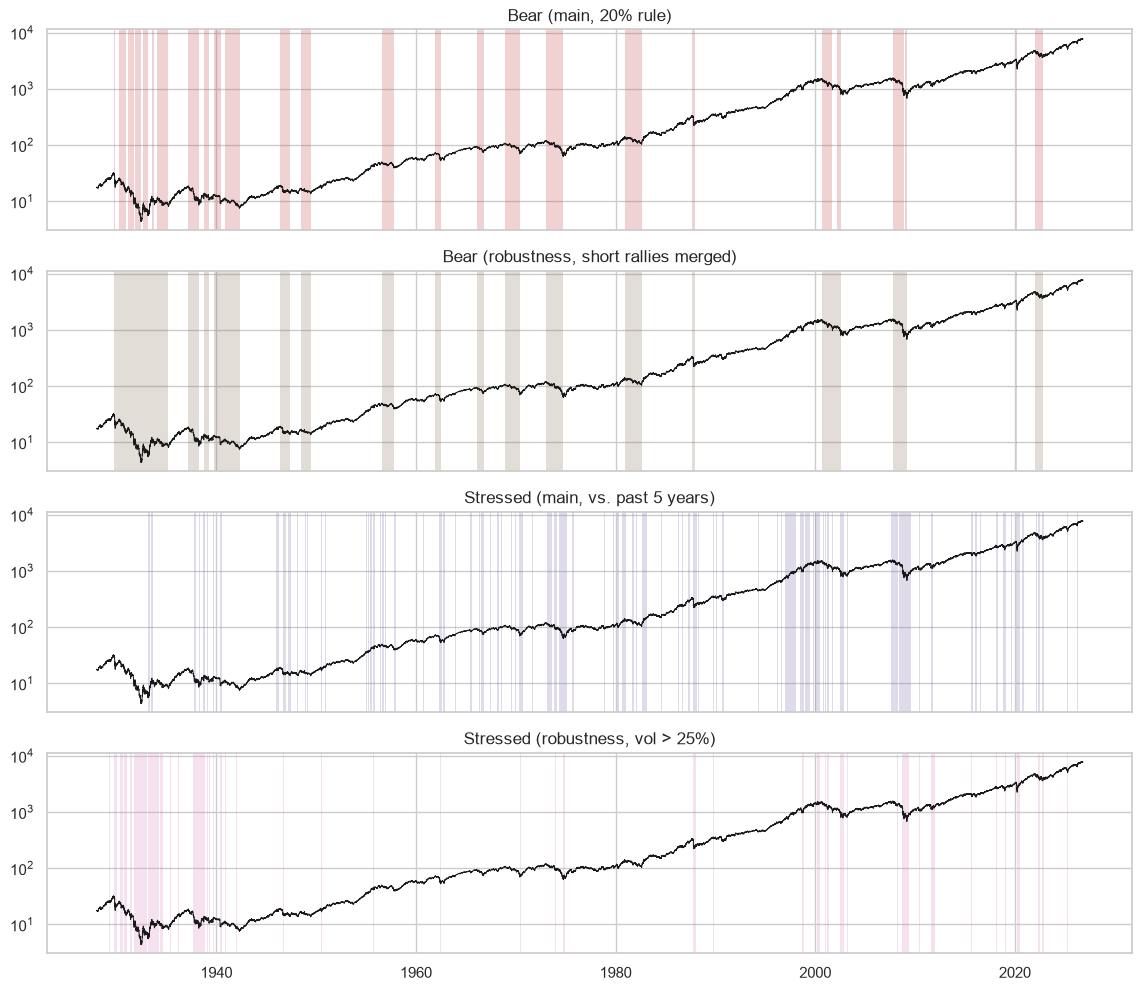

In [14]:
# Regime labels on the S&P 500
def shade(ax, label, color):
    for _, row in episodes(label).iterrows():
        ax.axvspan(row["start"], row["end"], color=color, alpha=0.25, lw=0)

panels = [("bear", "C3", "Bear (main, 20% rule)"), ("bear_merged", "C5", "Bear (robustness, short rallies merged)"),
          ("stressed", "C4", "Stressed (main, vs. past 5 years)"), ("stressed_fixed", "C6", "Stressed (robustness, vol > 25%)")]
fig, axes = plt.subplots(len(panels), 1, figsize=(14, 12), sharex=True)
for ax, (col, color, title) in zip(axes, panels):
    ax.plot(daily.index, daily["gspc_close"], color="k", lw=0.7)
    ax.set_yscale("log")
    shade(ax, table[col], color)
    ax.set_title(title)
plt.show()

## 5. EDA and statistical testing

In [15]:
r = np.log(daily["gspc_close"]).diff().dropna()
decade = (r.index.year // 10) * 10
print(f"1928-2026: annual return {r.mean()*252:.1%}, volatility {r.std()*np.sqrt(252):.1%}, "
      f"skew {stats.skew(r):.2f}, excess kurtosis {stats.kurtosis(r):.1f}")
r.groupby(decade).agg(annual_return=lambda s: s.mean() * 252, annual_vol=lambda s: s.std() * np.sqrt(252), worst_day="min")

1928-2026: annual return 6.2%, volatility 18.8%, skew -0.46, excess kurtosis 18.7


,annual_return,annual_vol,worst_day
date,,,
1920,0.098,0.287,-0.139
1930,-0.055,0.344,-0.096
1940,0.030,0.156,-0.104
1950,0.128,0.115,-0.068
1960,0.044,0.101,-0.069
1970,0.016,0.136,-0.037
1980,0.118,0.174,-0.229
1990,0.142,0.141,-0.071
2000,-0.028,0.222,-0.095


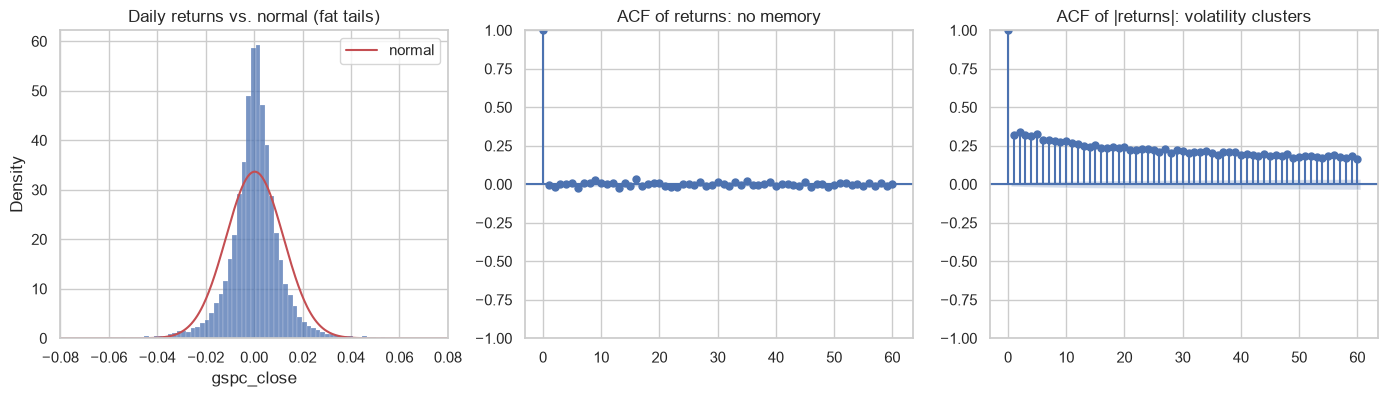

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(r, bins=200, stat="density", ax=axes[0])
x = np.linspace(-0.08, 0.08, 400)
axes[0].plot(x, norm.pdf(x, r.mean(), r.std()), color="C3", label="normal")
axes[0].set_xlim(-0.08, 0.08); axes[0].legend(); axes[0].set_title("Daily returns vs. normal (fat tails)")
plot_acf(r, lags=60, ax=axes[1], title="ACF of returns: no memory")
plot_acf(r.abs(), lags=60, ax=axes[2], title="ACF of |returns|: volatility clusters")
plt.show()

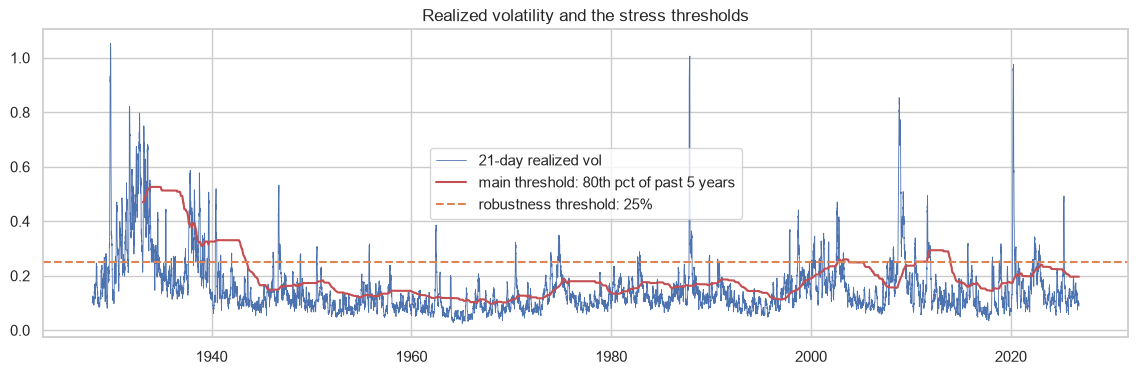

stressed share by decade (main label):
date
1920     NaN
1930   0.170
1940   0.148
1950   0.162
1960   0.181
1970   0.256
1980   0.299
1990   0.286
2000   0.318
2010   0.157
2020   0.192


In [17]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(table.index, table["rv_21d"], lw=0.6, label="21-day realized vol")
ax.plot(table.index, table["stress_threshold"], color="C3", label="main threshold: 80th pct of past 5 years")
ax.axhline(STRESS_FIXED_VOL, color="C1", ls="--", label="robustness threshold: 25%")
ax.legend(); ax.set_title("Realized volatility and the stress thresholds")
plt.show()
print("stressed share by decade (main label):")
print(table["stressed"].groupby((table.index.year // 10) * 10).mean().round(3).to_string())

In [18]:
# Persistence: how often is "no change" right, and how many future regime days are new?
rows = {}
for label in ["bear", "stressed"]:
    for h in HORIZONS:
        x = table[[label, f"target_{label}_h{h}"]].dropna()
        future = x.iloc[:, 1] == 1
        rows[f"{label}, {h}d"] = {"no-change accuracy": (x.iloc[:, 0] == x.iloc[:, 1]).mean(),
                                  "share of future regime days that are new": (future & (x.iloc[:, 0] == 0)).sum() / future.sum()}
pd.DataFrame(rows).T

,no-change accuracy,share of future regime days that are new
"bear, 5d",0.989,0.026
"bear, 21d",0.955,0.109
"stressed, 5d",0.932,0.155
"stressed, 21d",0.818,0.414


,calm in 21d,stressed in 21d,bull in 21d,bear in 21d
mom_3m,0.031,-0.014,0.035,-0.026
dist_ma200,0.046,-0.008,0.051,-0.034
drawdown,-0.106,-0.115,-0.080,-0.233
rv_21d,0.112,0.168,0.117,0.163


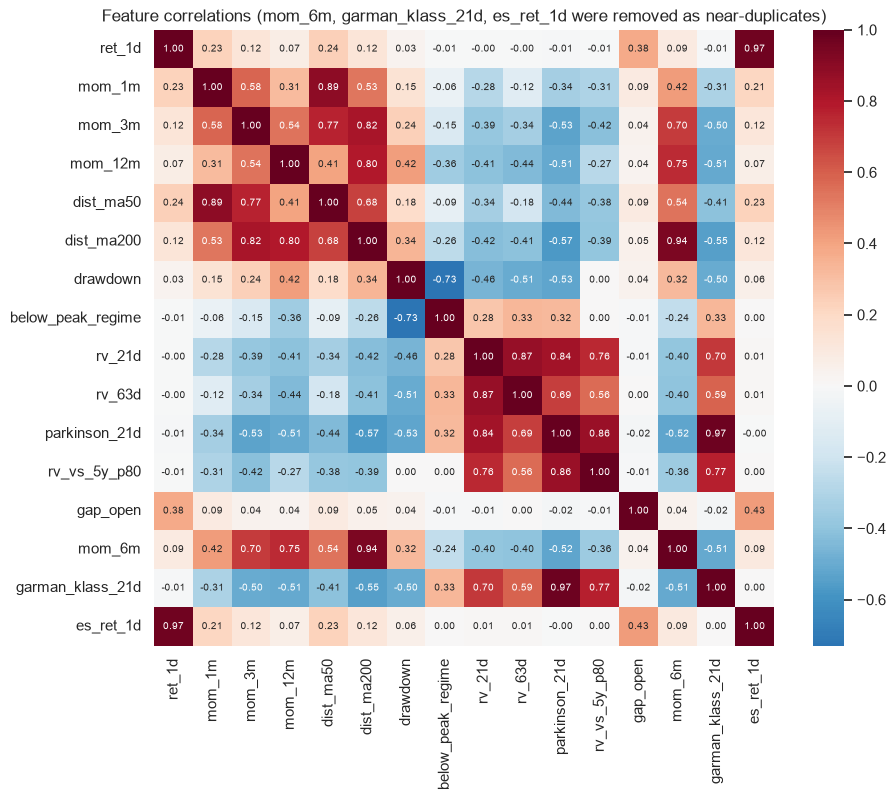

In [19]:
# Features today vs. the regime 21 days later, and feature correlations
cols = ["mom_3m", "dist_ma200", "drawdown", "rv_21d"]
med = pd.concat({"calm in 21d": table[table.target_stressed_h21 == 0][cols].median(),
                 "stressed in 21d": table[table.target_stressed_h21 == 1][cols].median(),
                 "bull in 21d": table[table.target_bear_h21 == 0][cols].median(),
                 "bear in 21d": table[table.target_bear_h21 == 1][cols].median()}, axis=1)
display(med)
cand = FEATURES_MAIN + ["mom_6m", "garman_klass_21d", "es_ret_1d"]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(table[cand].corr(), cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=ax, annot_kws={"size": 7})
ax.set_title("Feature correlations (mom_6m, garman_klass_21d, es_ret_1d were removed as near-duplicates)")
plt.show()

**Hypothesis tests** (`run_statistical_tests.py`). Test 1 uses the full history; Tests 2–4 use 1962–2021. Observations are autocorrelated and samples large, so read the effect sizes.

In [20]:
val = table.loc["1962":"2021"]

def mann_whitney(x, group):
    a, b = x[group == 1], x[group == 0]
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    return u.statistic, u.pvalue, 2 * u.statistic / (len(a) * len(b)) - 1, a.median(), b.median()

tests = []
for name, x in [("returns", r), ("absolute returns", r.abs())]:
    lb = acorr_ljungbox(x, lags=[20], return_df=True).iloc[0]
    tests.append({"test": f"Ljung-Box (20 lags), {name}", "statistic": lb.lb_stat, "p-value": lb.lb_pvalue,
                  "effect size": f"lag-1 autocorrelation {x.autocorr(1):+.3f}"})
c2 = val[["stressed", "target_stressed_h21"]].dropna()
ct = pd.crosstab(c2["stressed"], c2["target_stressed_h21"])
chi2, p, dof, expected = stats.chi2_contingency(ct, correction=False)
tests.append({"test": "Chi-square: stressed today vs. in 21 days", "statistic": chi2, "p-value": p,
              "effect size": f"Cramer's V = {np.sqrt(chi2 / ct.values.sum()):.2f}"})
for feat, target in [("rv_21d", "target_stressed_h21"), ("dist_ma200", "target_bear_h21")]:
    s = val[[feat, target]].dropna()
    U, p, rb, m1, m0 = mann_whitney(s[feat], s[target])
    tests.append({"test": f"Mann-Whitney: {feat} by {target}", "statistic": U, "p-value": p,
                  "effect size": f"r = {rb:+.2f} (medians {m1:+.1%} vs {m0:+.1%})"})
jb = stats.jarque_bera(r)
tests.append({"test": "Jarque-Bera normality of returns", "statistic": jb.statistic, "p-value": jb.pvalue, "effect size": ""})
pd.DataFrame(tests).set_index("test")

,statistic,p-value,effect size
test,,,
"Ljung-Box (20 lags), returns",98.433,0.000,lag-1 autocorrelation -0.007
"Ljung-Box (20 lags), absolute returns","37,890.506",0.000,lag-1 autocorrelation +0.318
Chi-square: stressed today vs. in 21 days,"3,804.924",0.000,Cramer's V = 0.50
Mann-Whitney: rv_21d by target_stressed_h21,"33,065,579.000",0.000,r = +0.52 (medians +16.7% vs +10.8%)
Mann-Whitney: dist_ma200 by target_bear_h21,"6,295,283.000",0.000,r = -0.57 (medians -4.0% vs +4.8%)
Jarque-Bera normality of returns,"361,599.081",0.000,


In [21]:
# Validation period vs. holdout period
comp = {}
for name, x in {"validation 1962-2021": val, "holdout 2022-2026": table.loc[HOLDOUT_START:]}.items():
    rr = x["ret_1d"].dropna()
    comp[name] = {"days": len(x), "annual return": rr.mean() * 252, "annual vol": rr.std() * np.sqrt(252),
                  "bear share": x["bear"].mean(), "stressed share (main)": x["stressed"].mean(),
                  "stressed share (fixed)": x["stressed_fixed"].mean(), "median rv_21d": x["rv_21d"].median(),
                  "deepest drawdown": x["drawdown"].min()}
ks = stats.ks_2samp(val["rv_21d"].dropna(), table.loc[HOLDOUT_START:, "rv_21d"].dropna())
print(f"KS test on rv_21d: D = {ks.statistic:.3f}, p = {ks.pvalue:.1e}")
pd.DataFrame(comp)

KS test on rv_21d: D = 0.176, p = 1.1e-30


,validation 1962-2021,holdout 2022-2026
days,"15,105.000","1,207.000"
annual return,0.070,0.098
annual vol,0.164,0.171
bear share,0.152,0.162
stressed share (main),0.257,0.155
stressed share (fixed),0.071,0.104
median rv_21d,0.118,0.136
deepest drawdown,-0.568,-0.254


## 6. Feature selection: SPY volume and VIX

First the validation and model code (`src/sp500/validation.py`, `src/sp500/models.py`), used here and in Parts 7–9. Bear labels are recomputed in each fold from the prices known at that time, because the bear label needs hindsight.

In [22]:
def walk_forward_splits(
    index: pd.DatetimeIndex,
    first_test_year: int,
    gap: int,
    last_test_year: int | None = None,
    holdout_start: str = HOLDOUT_START,
) -> Iterator[tuple[int, np.ndarray, np.ndarray]]:
    """Yield (test_year, train_idx, test_idx) as integer positions.

    Train = everything before the test year minus a `gap` of trading days (use gap >= horizon h,
    so overlapping targets cannot leak). Test = one calendar year. Years at or after
    `holdout_start` are never yielded.
    """
    index = pd.DatetimeIndex(index)
    holdout_year = pd.Timestamp(holdout_start).year
    last = min(last_test_year or index.max().year, holdout_year - 1)
    years = index.year
    for year in range(first_test_year, last + 1):
        test_idx = np.flatnonzero(years == year)
        if len(test_idx) == 0:
            continue
        train_end = test_idx[0] - gap
        if train_end <= 0:
            continue
        yield year, np.arange(train_end), test_idx

In [23]:
BASELINES = ("persistence", "ma200_rule", "hmm")


MODELS = ("logreg", "lightgbm", "svm")


CURRENT_STATE = {
    "bear": "below_peak_regime",
    "bear_merged": "below_peak_regime",
    "stressed": "stressed",
    "stressed_fixed": "stressed_fixed",
}


def make_model(name: str):
    """Fixed hyperparameters (no tuning, to avoid fitting the test years)."""
    if name == "logreg":
        return make_pipeline(RobustScaler(), LogisticRegression(C=1.0, max_iter=5000))
    if name == "lightgbm":
        from lightgbm import LGBMClassifier

        return LGBMClassifier(
            n_estimators=200, learning_rate=0.03, num_leaves=15, min_child_samples=200,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
            random_state=0, verbose=-1,
        )
    if name == "svm":
        # RBF SVM (as in the literature review), probabilities via Platt scaling fitted on
        # time-ordered splits of the training data
        svc = make_pipeline(RobustScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))
        return CalibratedClassifierCV(svc, method="sigmoid", cv=TimeSeriesSplit(n_splits=3))
    raise ValueError(name)


def fit_hmm(returns: np.ndarray):
    from hmmlearn.hmm import GaussianHMM

    m = GaussianHMM(n_components=2, covariance_type="diag", n_iter=200, random_state=0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m.fit(returns.reshape(-1, 1))
    return m


def hmm_filtered_probs(model, returns: np.ndarray) -> np.ndarray:
    """Causal forward filter: P(state_t | returns up to t). Columns ordered [calm, volatile]."""
    means = model.means_.ravel()
    sd = np.sqrt(np.asarray(model.covars_).reshape(len(means), -1)[:, 0])
    lik = norm.pdf(returns[:, None], means[None, :], sd[None, :]) + 1e-300
    a = model.transmat_
    p = model.startprob_.copy()
    out = np.empty_like(lik)
    for t in range(len(returns)):
        if t:
            p = p @ a
        p = p * lik[t]
        p /= p.sum()
        out[t] = p
    order = np.argsort(sd)  # calm first
    return out[:, order], a[np.ix_(order, order)]


def fold_bear_target(bear_price: pd.Series, label: str, horizon: int, cutoff: pd.Timestamp) -> pd.Series:
    """Bear target as it could have been computed with prices up to `cutoff` only."""
    known = bear_price.loc[:cutoff]
    bear = bear_market_labels(known, method="peak_to_trough")
    lab = merge_bear_episodes(bear, known) if label == "bear_merged" else bear
    target = lab.shift(-horizon)
    return target


def run_walk_forward(
    table: pd.DataFrame,
    bear_price: pd.Series,
    features: list[str],
    labels: tuple[str, ...],
    horizons: tuple[int, ...],
    first_test_year: int,
    gap: int,
    start: str,
    holdout_start: str,
    models: tuple[str, ...] = MODELS,
    log=print,
    allow_missing: tuple[str, ...] = (),
) -> pd.DataFrame:
    """Return long-format predictions: date, label, horizon, method, prob, truth, current.

    `allow_missing`: features that may be NaN (e.g. VIX before 1990). Rows are only required to
    have the other features. Use with LightGBM only, which handles missing values natively.
    """
    end = pd.Timestamp(holdout_start) - pd.Timedelta(days=1)
    data = table.loc[start:end]
    required = [f for f in features if f not in allow_missing]
    data = data[data[required].notna().all(axis=1)]
    rows = []

    splits = list(walk_forward_splits(data.index, first_test_year, gap, holdout_start=holdout_start))
    for k, (year, train_idx, test_idx) in enumerate(splits, 1):
        train, test = data.iloc[train_idx], data.iloc[test_idx]
        cutoff = data.index[test_idx[0] - 1]  # last day known when the test year starts

        # HMM fitted once per fold on training returns; filtered over the contiguous history
        hist = data.iloc[: test_idx[-1] + 1]
        hmm = fit_hmm(train["ret_1d"].to_numpy())
        filt, trans = hmm_filtered_probs(hmm, hist["ret_1d"].to_numpy())
        filt_test = filt[test_idx[0]: test_idx[-1] + 1]

        for label in labels:
            for h in horizons:
                truth = test[f"target_{label}_h{h}"]
                current = test[label]
                if label.startswith("bear"):
                    y_all = fold_bear_target(bear_price, label, h, cutoff)
                    y_train = y_all.reindex(train.index)
                else:
                    y_train = train[f"target_{label}_h{h}"]
                # a training row's target must be known at the cut-off
                target_date_ok = pd.Series(data.index, index=data.index).shift(-h).reindex(train.index) <= cutoff
                ok = y_train.notna() & target_date_ok
                X_tr, y_tr = train.loc[ok, features], y_train[ok].astype(int)

                preds = {
                    "persistence": test[CURRENT_STATE[label]].astype(float).to_numpy(),
                    "ma200_rule": (test["dist_ma200"] < 0).astype(float).to_numpy()
                    if label.startswith("bear") else np.full(len(test), np.nan),
                    "hmm": (filt_test @ np.linalg.matrix_power(trans, h))[:, 1],
                }
                for name in models:
                    if y_tr.nunique() < 2:
                        preds[name] = np.full(len(test), y_tr.mean() if len(y_tr) else np.nan)
                        continue
                    Xf, yf = (X_tr.iloc[::SVM_TRAIN_EVERY], y_tr.iloc[::SVM_TRAIN_EVERY]) \
                        if name == "svm" else (X_tr, y_tr)
                    model = make_model(name)
                    with warnings.catch_warnings():
                        warnings.simplefilter("ignore")
                        try:
                            model.fit(Xf, yf)
                        except ValueError:
                            # e.g. an early calibration split with only one class: fall back to
                            # the SVM's built-in Platt scaling
                            model = make_pipeline(RobustScaler(), SVC(kernel="rbf", C=1.0, gamma="scale",
                                                                      probability=True, random_state=0))
                            model.fit(Xf, yf)
                        preds[name] = model.predict_proba(test[features])[:, 1]

                for method, p in preds.items():
                    rows.append(pd.DataFrame({
                        "date": test.index, "label": label, "horizon": h, "method": method,
                        "prob": p, "truth": truth.to_numpy(), "current": current.to_numpy(),
                        "test_year": year,
                    }))
        log(f"      fold {k}/{len(splits)}: test {year} (train {len(train):,} rows up to {cutoff.date()})")
    return pd.concat(rows, ignore_index=True)


SCORE_KEYS = ["n_days", "base_rate", "pr_auc", "roc_auc", "brier", "onset_base_rate", "onset_pr_auc",
              "signal_flips_per_year", "true_flips_per_year"]


def score(group: pd.DataFrame) -> pd.Series:
    """Metrics for one (label, horizon, method). Always returns the same keys (NaN if n/a)."""
    out = dict.fromkeys(SCORE_KEYS, np.nan)
    g = group.dropna(subset=["prob", "truth"])
    if g.empty:  # e.g. the 200-day-MA rule, which only exists for bear targets
        return pd.Series(out)
    y, p = g["truth"].astype(int), g["prob"].clip(0, 1)
    years = g["date"].nunique() / TRADING_DAYS
    out.update({"n_days": len(g), "base_rate": y.mean()})
    if y.nunique() == 2:
        out["pr_auc"] = average_precision_score(y, p)
        out["roc_auc"] = roc_auc_score(y, p)
        out["brier"] = brier_score_loss(y, p)
    # onset: days not yet in the regime -> will it start within h days?
    o = g[g["current"] == 0]
    yo = o["truth"].astype(int)
    out["onset_base_rate"] = yo.mean()
    out["onset_pr_auc"] = average_precision_score(yo, o["prob"].clip(0, 1)) if yo.nunique() == 2 else np.nan
    # stability: switches per year of the 0.5-thresholded signal vs. of the truth
    sig = (g.sort_values("date")["prob"] >= 0.5).astype(int)
    out["signal_flips_per_year"] = sig.diff().abs().sum() / years
    out["true_flips_per_year"] = g.sort_values("date")["truth"].diff().abs().sum() / years
    return pd.Series(out)[SCORE_KEYS]


def lead_times(preds: pd.DataFrame, threshold: float = 0.5, window: int = 63) -> pd.DataFrame:
    """For each regime start in the test years: trading days of warning before it began.

    Warning = the number of consecutive days, ending the day before the start, on which the
    predicted probability was >= threshold (0 = no warning; capped at `window`).
    """
    rows = []
    for (label, h, method), g in preds.groupby(["label", "horizon", "method"]):
        g = g.sort_values("date").reset_index(drop=True)
        cur = g["current"].fillna(0).astype(int)
        starts = g.index[(cur == 1) & (cur.shift(1) == 0)]
        for s in starts:
            before = g["prob"].iloc[max(0, s - window): s] >= threshold
            run = 0
            for v in before[::-1]:
                if not v:
                    break
                run += 1
            rows.append({"label": label, "horizon": h, "method": method,
                         "start": g.loc[s, "date"], "warning_days": run})
    return pd.DataFrame(rows)

Each extra group is added to the 13 main features and compared on **identical rows** (training from 1993, test years 2000–2021), with logistic regression and LightGBM. **Rule, fixed before testing:** keep a group only if mean PR-AUC over the 4 main targets improves by ≥ 0.01 for both models and onset PR-AUC drops by no more than 0.01.

In [24]:
bear_price = bear_price_series(daily)
MAIN_LABELS, ROBUST_LABELS = ("bear", "stressed"), ("bear_merged", "stressed_fixed")

def mean_scores(preds, labels=MAIN_LABELS):
    m = preds.groupby(["label", "horizon", "method"]).apply(score, include_groups=False).reset_index()
    return m[m.label.isin(labels)].groupby("method")[["pr_auc", "onset_pr_auc"]].mean()

every = FEATURES_MAIN + [f for g in FEATURE_GROUPS.values() for f in g]
common = table[table[every].notna().all(axis=1)]
group_results = {}
for name, feats in {"base": FEATURES_MAIN, **{f"+ {g}": FEATURES_MAIN + cols for g, cols in FEATURE_GROUPS.items()}}.items():
    p = run_walk_forward(common, bear_price, feats, MAIN_LABELS, HORIZONS, 2000, WALK_FORWARD_GAP,
                         "1993-03-01", HOLDOUT_START, ("logreg", "lightgbm"), log=lambda m: None)
    group_results[name] = mean_scores(p[p.method.isin(["logreg", "lightgbm"])])
gr = pd.concat(group_results, names=["feature set"])
display(gr)
for g in FEATURE_GROUPS:
    gain = gr.loc[f"+ {g}", "pr_auc"] - gr.loc["base", "pr_auc"]
    onset = gr.loc[f"+ {g}", "onset_pr_auc"] - gr.loc["base", "onset_pr_auc"]
    keep = (gain >= GROUP_MIN_GAIN).all() and (onset >= -GROUP_MAX_ONSET_LOSS).all()
    print(f"{g}: PR-AUC gain {gain.round(3).to_dict()}, onset {onset.round(3).to_dict()} -> {'KEEP' if keep else 'DROP'}")

pr_auc  onset_pr_auc
feature set  method                        
base         lightgbm   0.527         0.138
             logreg     0.441         0.109
+ spy_volume lightgbm   0.529         0.149
             logreg     0.446         0.120
+ vix        lightgbm   0.545         0.156
             logreg     0.461         0.152

spy_volume: PR-AUC gain {'lightgbm': 0.002, 'logreg': 0.005}, onset {'lightgbm': 0.01, 'logreg': 0.011} -> DROP
vix: PR-AUC gain {'lightgbm': 0.018, 'logreg': 0.02}, onset {'lightgbm': 0.018, 'logreg': 0.043} -> KEEP


In [25]:
# VIX passes on the shared 1993+ sample. But can it beat the main model trained on the full 1962+ history?
# LightGBM from 1962 with the VIX features left missing before 1990, same test years 2000-2021:
hyb = {}
for name, feats, missing in [("main", FEATURES_MAIN, ()), ("main + vix (missing before 1990)",
                             FEATURES_MAIN + FEATURE_GROUPS["vix"], tuple(FEATURE_GROUPS["vix"]))]:
    p = run_walk_forward(table, bear_price, feats, MAIN_LABELS, HORIZONS, 2000, WALK_FORWARD_GAP, MODEL_START,
                         HOLDOUT_START, ("lightgbm",), log=lambda m: None, allow_missing=missing)
    hyb[name] = mean_scores(p[p.method == "lightgbm"]).loc["lightgbm"]
hyb = pd.DataFrame(hyb).T
display(hyb)
print(f"gain from VIX on the full history: {hyb.iloc[1]['pr_auc'] - hyb.iloc[0]['pr_auc']:+.3f} -> "
      f"VIX is not used; the final model keeps the {len(FEATURES_MAIN)} main features")

,pr_auc,onset_pr_auc
main,0.559,0.160
main + vix (missing before 1990),0.540,0.160


gain from VIX on the full history: -0.018 -> VIX is not used; the final model keeps the 13 main features


## 7. Modeling: walk-forward validation, 1980–2021

For each test year *N* = 1980…2021: train on 1962 → *N* − 1 (21-day gap), predict year *N*. Three baselines and three models, 4 labels × 2 horizons. About 2 minutes.

In [26]:
t0 = time.time()
preds = run_walk_forward(table, bear_price, FEATURES_MAIN, MAIN_LABELS + ROBUST_LABELS, HORIZONS, FIRST_TEST_YEAR,
                         WALK_FORWARD_GAP, MODEL_START, HOLDOUT_START, MODELS, log=lambda m: None)
print(f"{len(preds):,} out-of-sample predictions in {time.time() - t0:.0f}s")
metrics = preds.groupby(["label", "horizon", "method"]).apply(score, include_groups=False).reset_index()
order = list(BASELINES) + list(MODELS)
print("PR-AUC (main labels):")
metrics[metrics.label.isin(MAIN_LABELS)].pivot_table(index="method", columns=["label", "horizon"], values="pr_auc").reindex(order)

507,408 out-of-sample predictions in 98s


PR-AUC (main labels):


label        bear       stressed      
horizon        5     21       5     21
method                                
persistence 0.131 0.122    0.776 0.512
ma200_rule  0.299 0.261      NaN   NaN
hmm         0.277 0.280    0.749 0.531
logreg      0.361 0.293    0.930 0.661
lightgbm    0.358 0.340    0.927 0.648
svm         0.355 0.313    0.847 0.555

In [27]:
print("Onset PR-AUC (days not yet in the regime) and Brier score (main labels):")
display(metrics[metrics.label.isin(MAIN_LABELS)].pivot_table(index="method", columns=["label", "horizon"],
                                                             values="onset_pr_auc").reindex(order))
display(metrics[metrics.label.isin(MAIN_LABELS)].pivot_table(index="method", columns=["label", "horizon"],
                                                             values="brier").reindex(order))
print("PR-AUC (robustness labels):")
metrics[metrics.label.isin(ROBUST_LABELS)].pivot_table(index="method", columns=["label", "horizon"], values="pr_auc").reindex(order)

Onset PR-AUC (days not yet in the regime) and Brier score (main labels):


label        bear       stressed      
horizon        5     21       5     21
method                                
persistence 0.004 0.017    0.051 0.128
ma200_rule  0.004 0.018      NaN   NaN
hmm         0.006 0.044    0.149 0.191
logreg      0.005 0.032    0.282 0.260
lightgbm    0.003 0.014    0.278 0.265
svm         0.005 0.019    0.220 0.211

label        bear       stressed      
horizon        5     21       5     21
method                                
persistence 0.321 0.335    0.075 0.188
ma200_rule  0.187 0.204      NaN   NaN
hmm         0.167 0.116    0.111 0.161
logreg      0.094 0.100    0.057 0.143
lightgbm    0.101 0.103    0.059 0.148
svm         0.087 0.091    0.083 0.157

PR-AUC (robustness labels):


label       bear_merged       stressed_fixed      
horizon              5     21             5     21
method                                            
persistence       0.164 0.152          0.724 0.315
ma200_rule        0.350 0.312            NaN   NaN
hmm               0.313 0.309          0.426 0.264
logreg            0.395 0.338          0.864 0.563
lightgbm          0.363 0.335          0.897 0.487
svm               0.362 0.320          0.812 0.415

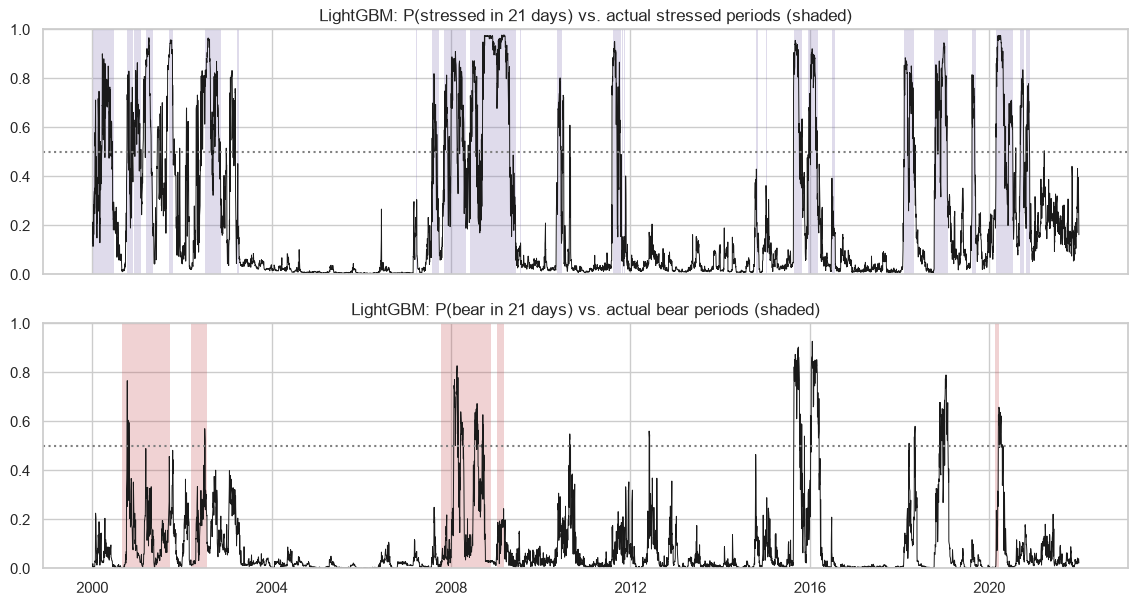

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, label, color in [(axes[0], "stressed", "C4"), (axes[1], "bear", "C3")]:
    g = preds[(preds.label == label) & (preds.horizon == 21) & (preds.method == "lightgbm")].set_index("date").loc["2000":]
    shade(ax, table.loc[g.index.min():g.index.max(), label], color)
    ax.plot(g.index, g["prob"], color="k", lw=0.7)
    ax.axhline(0.5, color="grey", ls=":")
    ax.set_ylim(0, 1)
    ax.set_title(f"LightGBM: P({label} in 21 days) vs. actual {label} periods (shaded)")
plt.show()

## 8. Interpretation and per-crisis results

Models refit on 1962–2021 for the 21-day targets (bear labels recomputed from prices up to 2021-12-31). LightGBM's built-in SHAP values (`pred_contrib`) give each feature's contribution.

In [29]:
H = 21
NICE = {
    "ret_1d": "1-day return", "mom_1m": "1-month momentum", "mom_3m": "3-month momentum",
    "mom_12m": "12-month momentum", "dist_ma50": "distance from 50-day MA",
    "dist_ma200": "distance from 200-day MA", "drawdown": "drawdown from peak",
    "below_peak_regime": "20% below old peak (flag)", "rv_21d": "21-day realized vol",
    "rv_63d": "63-day realized vol", "parkinson_21d": "21-day high-low vol",
    "rv_vs_5y_p80": "vol vs. stress threshold", "gap_open": "overnight gap",
}


FEATURE_GROUPS_INTERP = {
    "Volatility": ["rv_vs_5y_p80", "rv_21d", "rv_63d", "parkinson_21d"],
    "Trend / momentum": ["dist_ma50", "dist_ma200", "mom_1m", "mom_3m", "mom_12m"],
    "Drawdown": ["drawdown", "below_peak_regime"],
    "Daily moves": ["ret_1d", "gap_open"],
}


def training_set(table, bear_price, target, cutoff):
    data = table.loc[MODEL_START:cutoff]
    data = data[data[FEATURES_MAIN].notna().all(axis=1)]
    if target == "bear":
        y = fold_bear_target(bear_price, "bear", H, cutoff).reindex(data.index)
    else:
        y = data[f"target_{target}_h{H}"]
    target_date = pd.Series(data.index, index=data.index).shift(-H)
    ok = y.notna() & (target_date <= cutoff)
    return data.loc[ok, FEATURES_MAIN], y[ok].astype(int)


cutoff = pd.Timestamp(HOLDOUT_START) - pd.Timedelta(days=1)
coefs, shares = {}, {}
for target in ["stressed", "bear"]:
    X, y = training_set(table, bear_price, target, cutoff)
    coefs[target] = pd.Series(make_model("logreg").fit(X, y)[-1].coef_[0], index=FEATURES_MAIN)
    lgb = make_model("lightgbm").fit(X, y)
    shap_abs = pd.DataFrame(lgb.booster_.predict(X, pred_contrib=True)[:, :-1], columns=FEATURES_MAIN).abs().mean()
    shares[target] = {grp: shap_abs[f].sum() / shap_abs.sum() for grp, f in FEATURE_GROUPS_INTERP.items()}
print("Share of LightGBM SHAP importance by feature group:")
display(pd.DataFrame(shares).style.format("{:.0%}"))
print("Logistic regression coefficients (per interquartile range of each feature):")
pd.DataFrame(coefs).sort_values("stressed", key=np.abs, ascending=False)

Share of LightGBM SHAP importance by feature group:


,stressed,bear
Volatility,51%,41%
Trend / momentum,30%,33%
Drawdown,13%,24%
Daily moves,6%,2%


Logistic regression coefficients (per interquartile range of each feature):


,stressed,bear
rv_vs_5y_p80,1.984,-0.076
rv_21d,-1.235,-1.085
rv_63d,0.865,-0.043
below_peak_regime,-0.656,-1.523
dist_ma50,-0.559,0.094
parkinson_21d,0.458,1.874
mom_3m,0.319,0.146
mom_1m,-0.262,-0.135
ret_1d,-0.149,-0.031
dist_ma200,0.128,-1.447


In [30]:
STRESS_CRISES = {
    "1987 crash": ("1987-08-01", "1987-12-31"),
    "1990 Gulf War": ("1990-07-01", "1990-12-31"),
    "1997 Asian crisis": ("1997-10-01", "1997-12-31"),
    "1998 LTCM / Russia": ("1998-07-15", "1998-11-30"),
    "2000 dot-com top": ("2000-03-01", "2000-06-30"),
    "2001 9/11": ("2001-09-01", "2001-10-31"),
    "2002 accounting scandals": ("2002-06-01", "2002-10-31"),
    "2007 subprime start": ("2007-07-15", "2007-09-30"),
    "2008 Lehman": ("2008-09-01", "2008-12-31"),
    "2010 flash crash / euro": ("2010-04-20", "2010-07-31"),
    "2011 US downgrade": ("2011-07-20", "2011-10-31"),
    "2015 China devaluation": ("2015-08-01", "2015-10-31"),
    "2018 Volmageddon": ("2018-01-25", "2018-04-30"),
    "2018 Q4 sell-off": ("2018-10-01", "2018-12-31"),
    "2020 COVID": ("2020-02-15", "2020-05-31"),
}


def signal_offset(g: pd.DataFrame, start_pos: int, look: int = 42) -> str:
    """Trading days from the regime start to the start of the method's >= 50% signal.

    Negative = warned in advance. '≤ -42' = signal already on 42 days before. 'missed' = no
    signal within 42 days after the start.
    """
    p = g["prob"].to_numpy()
    lo, hi = max(0, start_pos - look), min(len(p), start_pos + look + 1)
    window = p[lo:hi] >= 0.5
    rel = np.arange(lo, hi) - start_pos
    if not window.any():
        return "missed"
    # the signal "episode" that covers or follows the start
    on = np.where(window)[0]
    after = on[rel[on] >= 0]
    k = after[0] if len(after) else on[-1]
    while k > 0 and window[k - 1]:
        k -= 1
    if k == 0 and lo == start_pos - look and window[0]:
        return f"≤ {-look}"
    return f"{rel[k]:+d}"


def stress_crisis_table(preds, table):
    rows = []
    for name, (a, b) in STRESS_CRISES.items():
        lab = table["stressed"]
        w = lab.loc[a:b]
        prev = lab.shift(1).loc[a:b]
        starts = w.index[(w == 1) & (prev == 0)]
        if len(starts) == 0:
            starts = w.index[w == 1][:1]
        if len(starts) == 0:
            continue
        start = starts[0]
        dd = table.loc[a:b, "drawdown"].min()
        row = {"crisis": name, "stress start": start.date(), "max drawdown": dd}
        for m in ("persistence", "hmm", "logreg", "lightgbm"):
            g = preds[(preds.label == "stressed") & (preds.horizon == H) & (preds.method == m)] \
                .sort_values("date").reset_index(drop=True)
            pos = g.index[g.date == start]
            if len(pos) == 0:
                row[m] = "n/a"
                continue
            row[m] = signal_offset(g, int(pos[0]))
            if m in ("logreg", "lightgbm"):
                before = g.iloc[max(0, pos[0] - 21): pos[0]]["prob"].mean()
                row[f"{m}_prob_before"] = before
        rows.append(row)
    return pd.DataFrame(rows)


crises = stress_crisis_table(preds, table)
print("Days from the first stressed day to the models' 50% signal (negative = warned in advance):")
crises[["crisis", "stress start", "hmm", "logreg", "lightgbm"]]

Days from the first stressed day to the models' 50% signal (negative = warned in advance):


,crisis,stress start,hmm,logreg,lightgbm
0,1987 crash,1987-09-01,+0,+24,+30
1,1990 Gulf War,1990-08-08,missed,-2,-2
2,1997 Asian crisis,1997-10-21,missed,+2,+4
3,1998 LTCM / Russia,1998-07-30,missed,+1,+3
4,2000 dot-com top,2000-03-01,missed,+4,+4
5,2001 9/11,2001-09-17,-3,+3,-7
6,2002 accounting scandals,2002-06-03,+0,+26,+0
7,2007 subprime start,2007-07-27,-1,+2,+2
8,2008 Lehman,2008-09-02,-2,+2,+2
9,2010 flash crash / euro,2010-05-10,-4,+8,+8


## 9. Final holdout test, 2022–2026

The holdout was set aside at the start and used **once**, on 2026-10-27, with the setup fixed beforehand (report Chapter 6.6). This cell re-runs exactly that test: the same setup, refit each January, so it reproduces the report's numbers; nothing here was used to make any decision.

In [31]:
def block_bootstrap_diff(g_model, g_base, n_rep=1000, block=63, seed=0):
    """95% CI for PR-AUC(model) - PR-AUC(baseline), resampling blocks of consecutive days."""
    a = g_model.dropna(subset=["prob", "truth"]).set_index("date")
    b = g_base.dropna(subset=["prob", "truth"]).set_index("date")
    idx = a.index.intersection(b.index)
    y, pa, pb = a.loc[idx, "truth"].to_numpy(int), a.loc[idx, "prob"].to_numpy(), b.loc[idx, "prob"].to_numpy()
    n = len(y)
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_rep):
        starts = rng.integers(0, n - block, size=int(np.ceil(n / block)))
        s = np.concatenate([np.arange(k, k + block) for k in starts])[:n]
        if y[s].min() == y[s].max():
            continue
        diffs.append(average_precision_score(y[s], pa[s]) - average_precision_score(y[s], pb[s]))
    point = average_precision_score(y, pa) - average_precision_score(y, pb)
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return point, lo, hi


hold = run_walk_forward(table, bear_price, FEATURES_MAIN, MAIN_LABELS + ROBUST_LABELS, HORIZONS,
                        pd.Timestamp(HOLDOUT_START).year, WALK_FORWARD_GAP, MODEL_START,
                        holdout_start="2100-01-01", models=MODELS, log=lambda m: None)
hold = hold[hold.date >= HOLDOUT_START]
hm = hold.groupby(["label", "horizon", "method"]).apply(score, include_groups=False).reset_index()
print(f"holdout: {hold.dropna(subset=['truth']).date.min().date()} -> {hold.dropna(subset=['truth']).date.max().date()}")
hm[hm.label.isin(MAIN_LABELS)].pivot_table(index="method", columns=["label", "horizon"], values="pr_auc").reindex(order)

holdout: 2022-01-03 -> 2026-10-16


label        bear       stressed      
horizon        5     21       5     21
method                                
persistence 0.181 0.156    0.780 0.384
ma200_rule  0.465 0.413      NaN   NaN
hmm         0.464 0.359    0.687 0.485
logreg      0.481 0.433    0.938 0.549
lightgbm    0.448 0.345    0.947 0.590
svm         0.612 0.534    0.954 0.602

In [32]:
rows = []
for label in MAIN_LABELS:
    for h in HORIZONS:
        sub = hm[(hm.label == label) & (hm.horizon == h)].set_index("method")
        best = sub.loc[list(BASELINES), "pr_auc"].dropna().idxmax()
        for model in ("logreg", "lightgbm"):
            g = hold[(hold.label == label) & (hold.horizon == h)]
            d, lo, hi = block_bootstrap_diff(g[g.method == model], g[g.method == best])
            rows.append({"target": f"{label} {h}d", "model": model, "best baseline": best,
                         "gain": d, "95% CI low": lo, "95% CI high": hi})
pd.DataFrame(rows)

,target,model,best baseline,gain,95% CI low,95% CI high
0,bear 5d,logreg,ma200_rule,0.016,-0.222,0.322
1,bear 5d,lightgbm,ma200_rule,-0.018,-0.130,0.172
2,bear 21d,logreg,ma200_rule,0.020,-0.261,0.378
3,bear 21d,lightgbm,ma200_rule,-0.068,-0.188,0.172
4,stressed 5d,logreg,persistence,0.158,0.097,0.281
5,stressed 5d,lightgbm,persistence,0.167,0.107,0.283
6,stressed 21d,logreg,hmm,0.064,-0.136,0.350
7,stressed 21d,lightgbm,hmm,0.105,-0.056,0.343


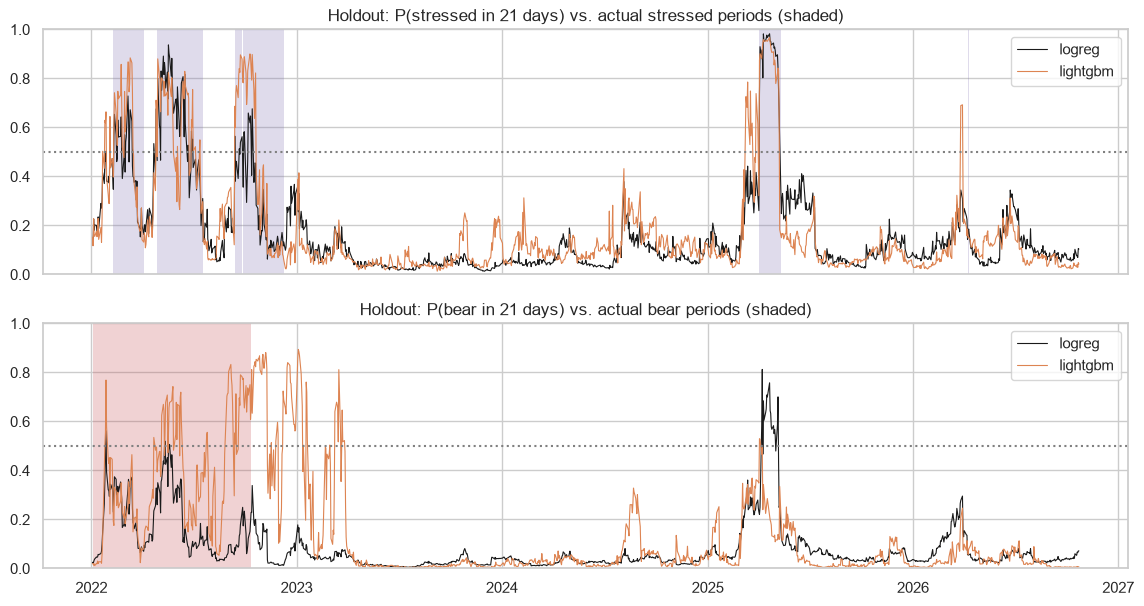

notebook run time: 3.9 minutes


In [33]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, label, color in [(axes[0], "stressed", "C4"), (axes[1], "bear", "C3")]:
    shade(ax, table.loc[HOLDOUT_START:, label], color)
    for m, c in [("logreg", "k"), ("lightgbm", "C1")]:
        g = hold[(hold.label == label) & (hold.horizon == 21) & (hold.method == m)]
        ax.plot(g.date, g.prob, color=c, lw=0.8, label=m)
    ax.axhline(0.5, color="grey", ls=":")
    ax.set_ylim(0, 1)
    ax.legend(loc="upper right")
    ax.set_title(f"Holdout: P({label} in 21 days) vs. actual {label} periods (shaded)")
plt.show()
print(f"notebook run time: {(time.time() - NOTEBOOK_START) / 60:.1f} minutes")

## 10. Conclusions

1. **Short-term stress is reliably predictable.** For "stressed within 5 days", the models beat every baseline in 42 years of walk-forward validation (PR-AUC 0.93 vs. 0.78) and in the untouched 2022–2026 holdout (0.94–0.95 vs. 0.78; the bootstrap interval of the gain is above zero).
2. **One-month stress:** the models lead (validation 0.66 vs. 0.51) and are much better at predicting stress *starting*, but the holdout is too short to make this conclusive.
3. **Bear-market starts are not predictable.** The models recognize bear markets after the fall has begun and tie with the 200-day-moving-average rule.
4. **Volatility clustering drives about half of every prediction**; trend and drawdown most of the rest.
5. **Simple is enough:** logistic regression matches LightGBM and beats the SVM in validation; a long training history beats extra data (SPY volume, VIX).

Limitations: few bear markets (7 in the test years, 1 in the holdout), results depend on the label definitions, one data source, and no trading test. Full discussion: the written report and `docs/01–07` in the repository.